# Task 1.4 — Switching Hybrid Recommender

The weighted hybrid developed in Task 1.3 combines the scores of multiple
individual recommenders.

In this task, a switching hybrid is investigated. Instead of combining model
scores, the system selects a recommender based on the amount of information
available for a user.

Users with fewer training interactions may benefit from a popularity-based
recommender, while users with richer interaction histories can be handled by
a personalized recommender.

The switching rule is:

- Sparse users → Popular recommender
- Other users → Best personalized recommender

The switching threshold is selected using the validation set.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recbole.config import Config
from recbole.data import create_dataset, data_preparation

In [20]:
CONFIG_PATH = "../recbole/config/FISM/ml-100k.yaml"

config = Config(
    model="FISM",
    dataset="ml-100k",
    config_file_list=[CONFIG_PATH]
)

dataset = create_dataset(config)

train_data, valid_data, test_data = data_preparation(
    config,
    dataset
)

In [21]:
print(type(train_data))
print(type(train_data.dataset))

print("Full dataset:", len(dataset))
print("Train dataset:", len(train_data.dataset))
print("Valid dataset:", len(valid_data.dataset))
print("Test dataset:", len(test_data.dataset))

<class 'recbole.data.dataloader.general_dataloader.TrainDataLoader'>
<class 'recbole.data.dataset.dataset.Dataset'>
Full dataset: 100000
Train dataset: 80808
Valid dataset: 9596
Test dataset: 9596


In [22]:
# Get the training interaction matrix
train_matrix = train_data.dataset.inter_matrix(form="csr")

# Number of training interactions for each user
user_interaction_counts = np.diff(train_matrix.indptr)

print("Number of users (including padding):", len(user_interaction_counts))

# Ignore RecBole's padding user (ID 0) when describing the distribution
pd.Series(user_interaction_counts[1:]).describe()

Number of users (including padding): 944


count    943.000000
mean      85.692471
std       80.804939
min       16.000000
25%       27.000000
50%       53.000000
75%      120.000000
max      591.000000
dtype: float64

In [23]:
uid_field = train_data.dataset.uid_field

for uid in range(1, 11):
    external_uid = train_data.dataset.id2token(uid_field, uid)

    print(
        f"User {external_uid}: "
        f"{user_interaction_counts[uid]} training interactions"
    )

User 196: 33 training interactions
User 186: 74 training interactions
User 22: 104 training interactions
User 244: 192 training interactions
User 166: 16 training interactions
User 298: 103 training interactions
User 115: 74 training interactions
User 253: 79 training interactions
User 305: 178 training interactions
User 6: 169 training interactions


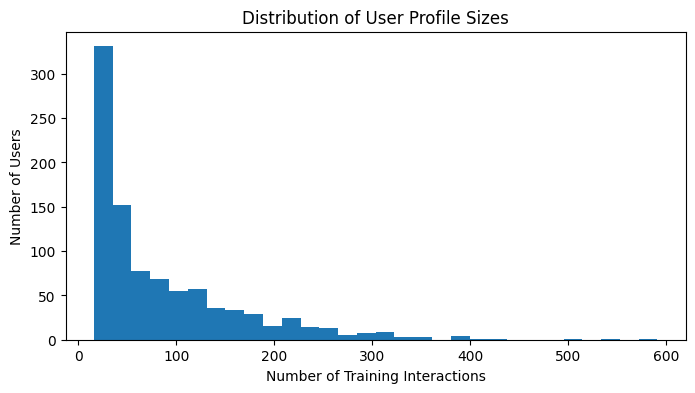

In [24]:
plt.figure(figsize=(8, 4))

plt.hist(user_interaction_counts[1:], bins=30)

plt.xlabel("Number of Training Interactions")
plt.ylabel("Number of Users")
plt.title("Distribution of User Profile Sizes")

plt.show()

In [25]:
counts = pd.Series(user_interaction_counts[1:])

thresholds = [20, 30, 40, 50, 75, 100]

threshold_summary = []

for threshold in thresholds:
    n_sparse = (counts < threshold).sum()
    pct_sparse = n_sparse / len(counts)

    threshold_summary.append({
        "threshold": threshold,
        "sparse_users": n_sparse,
        "active_users": len(counts) - n_sparse,
        "sparse_percentage": pct_sparse
    })

threshold_df = pd.DataFrame(threshold_summary)
threshold_df

,threshold,sparse_users,active_users,sparse_percentage
0,20,100,843,0.106045
1,30,265,678,0.281018
2,40,363,580,0.384942
3,50,451,492,0.478261
4,75,562,381,0.595970
5,100,650,293,0.689290


In [ ]:
# add ease 